# Mutual Fund Overview & Insights
**Name:** Stuti Goyal 

## Stage 0: Project Goal & Problem Statement

**1. Goal.** The goal is to analyse Indian mutual fund schemes and shortlist the 30 with the best balance of return, risk and cost, then present the findings in an interactive dashboard. Everyday investors benefit because it turns a long, confusing list of funds into a short, evidence-based list.

**2. Why balance return and risk.** Ranking by return alone rewards funds that took big risks and just got lucky. For example, a small-cap fund with a very high 3-year return can fall sharply in a bad year, and its expense ratio eats into what the investor actually keeps. A fund with a slightly lower return but low risk and low cost can be the better choice.

**3. Objectives.**
1. Clean the raw data (missing values, wrong formats, bad records).
2. Explore distributions and outliers to understand a typical fund.
3. Normalise the key metrics to a common 0–1 scale.
4. Build a scoring formula and rank all funds.
5. Export the Top 30 to Excel.
6. Build a Power BI dashboard and write the insights.

**4. Role of each tool.** Python (pandas, scikit-learn) cleans the data and calculates the scores. Excel holds the final Top 30 in a format that is easy to share. Power BI turns the results into interactive visuals for a non-technical audience. Each tool does what it is best at.

## Stage 1: Data Cleaning (Python)
### 1.1 Import the dataset
I load the CSV with pandas and check its size, column names and data types.

In [1]:
import pandas as pd
import numpy as np
pd.set_option("display.max_columns", None)

DATA_PATH = "data/comprehensive_mutual_funds_data.csv"
df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)

Rows, columns: (814, 20)


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 814 entries, 0 to 813
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   scheme_name    814 non-null    object 
 1   min_sip        814 non-null    int64  
 2   min_lumpsum    814 non-null    int64  
 3   expense_ratio  814 non-null    float64
 4   fund_size_cr   814 non-null    float64
 5   fund_age_yr    814 non-null    int64  
 6   fund_manager   814 non-null    object 
 7   sortino        814 non-null    object 
 8   alpha          814 non-null    object 
 9   sd             814 non-null    object 
 10  beta           814 non-null    object 
 11  sharpe         814 non-null    object 
 12  risk_level     814 non-null    int64  
 13  amc_name       814 non-null    object 
 14  rating         814 non-null    int64  
 15  category       814 non-null    object 
 16  sub_category   814 non-null    object 
 17  returns_1yr    814 non-null    float64
 18  returns_3y

In [3]:
df.head()

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr
0,Aditya Birla SL Active Debt Multi-Mgr FoF-Dir ...,100,100,0.27,10.0,10,Kaustubh Gupta,0.32,2.24,9.39,0.01,0.24,3,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,4.0,6.5,6.9
1,Aditya Birla SL Arbitrage Fund,1000,1000,0.36,4288.0,10,Lovelish Solanki,1.33,1.53,0.72,0.56,1.1,1,Aditya Birla Sun Life Mutual Fund,3,Hybrid,Arbitrage Mutual Funds,5.6,4.8,5.5
2,Aditya Birla SL Asset Allocator FoF-Dir Growth,1000,1000,0.53,157.0,10,Vinod Narayan Bhat,3.44,2.67,10.58,0.67,1.42,5,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,2.0,18.9,9.7
3,Aditya Birla SL Bal Bhavishya Yojna – Dir Growth,500,1000,0.76,637.0,4,Atul Penkar,2.18,-6.37,14.99,0.85,0.9,6,Aditya Birla Sun Life Mutual Fund,2,Solution Oriented,Childrens Funds,-0.7,17.1,NaN
4,Aditya Birla SL Balanced Advantage Fund,100,100,0.61,6386.0,10,Mohit Sharma,3.69,1.99,10.38,0.68,1.39,6,Aditya Birla Sun Life Mutual Fund,4,Hybrid,Dynamic Asset Allocation or Balanced Advantage,4.5,18.6,9.7


The dataset has **814 rows and 20 columns**. Key columns:
- `scheme_name`, `amc_name` (fund house), `fund_manager`
- `category` (Equity / Debt / Hybrid / Other / Solution Oriented) and `sub_category`
- `returns_1yr`, `returns_3yr`, `returns_5yr` (% returns)
- `expense_ratio` (% yearly cost), `fund_size_cr` (AUM in ₹ crore), `fund_age_yr`
- `risk_level` (1 = lowest, 6 = highest), `rating` (0 = unrated, 5 = best)
- `min_sip`, `min_lumpsum` (minimum investment amounts)
- `sd`, `beta`, `alpha`, `sharpe`, `sortino` (statistical risk measures)

### 1.2 Remove unnecessary columns

In [4]:
risk_cols = ["sortino", "alpha", "beta", "sharpe"]

# How many "-" placeholders in each advanced ratio?
print("Missing ('-') values in the advanced ratios:")
print((df[risk_cols] == "-").sum())

# Are the beta values sensible?
beta_num = pd.to_numeric(df["beta"], errors="coerce")
print(beta_num.describe())
print("\nBeta range:", beta_num.min(), "to", beta_num.max())
print("Beta typical value (median):", beta_num.median())

print("\nreturns_5yr missing:", df["returns_5yr"].isna().sum(), "of", len(df),
      f"({df['returns_5yr'].isna().mean()*100:.1f}%)")

# Funds with extreme beta (more than 5 away from zero)
df.loc[beta_num.abs() > 5, ["scheme_name", "category", "beta", "sd", "returns_1yr"]]


Missing ('-') values in the advanced ratios:
sortino    23
alpha      42
beta       42
sharpe     23
dtype: int64
count    772.000000
mean       0.822241
std        1.309871
min      -31.860000
25%        0.700000
50%        0.860000
75%        0.970000
max        5.400000
Name: beta, dtype: float64

Beta range: -31.86 to 5.4
Beta typical value (median): 0.86

returns_5yr missing: 167 of 814 (20.5%)


,scheme_name,category,beta,sd,returns_1yr
85,Bandhan FTP – Sr.179,Debt,5.4,3.98,4.4
89,Bank of India Credit Risk Fund,Debt,-31.86,77.72,130.8
324,ICICI Pru Long Term Equity Fund,Equity,5.04,4.06,-0.2
632,SBI FMP – Series 1 (3668 Days) – Direct Growth,Debt,5.09,3.62,4.8


I drop `sortino`, `alpha`, `beta` and `sharpe`:
- They are advanced ratios that my scoring formula (3-year return, expense ratio, fund age, 1-year return) and the dashboard do not use.
- The cell above shows each has 23–42 "-" placeholders (sortino 23, alpha 42, beta 42, sharpe 23).
- `beta` also has extreme values, from −31.86 to 5.4, while most funds are between 0.7 and 1.0. The −31.86 comes from a credit risk fund that also shows a 130.8% 1-year return, which looks like a data error.

I keep `sd` as my volatility measure. `returns_5yr` is also not needed (167 missing, about 20%), but I keep it until Step 1.4 because I use it to detect bad rows.

In [5]:
df = df.drop(columns=["sortino", "alpha", "beta", "sharpe"])
print("Columns left:", df.shape[1])

Columns left: 16


### 1.3 Identify missing values
`isna()` only finds blank cells, but this dataset also uses a "-" text placeholder. I count both.

In [6]:
missing = pd.DataFrame({
    "blank (NaN)": df.isna().sum(),
    "dash '-'": (df == "-").sum(),
})
missing["total missing"] = missing.sum(axis=1)
missing["% missing"] = (missing["total missing"] / len(df) * 100).round(1)
missing[missing["total missing"] > 0]

,blank (NaN),dash '-',total missing,% missing
sd,0,24,24,2.9
returns_3yr,21,0,21,2.6
returns_5yr,167,0,167,20.5


Missing data: `returns_5yr` (167 blank, 20.5%), `returns_3yr` (21 blank, 2.6%) and `sd` (24 "-" values, 2.9%). These are mostly new funds with too little history. **Strategy:** I do not fill them with an average, because that would invent performance numbers. I keep these funds for the dashboard and exclude them only from ranking, where a 3-year return is required.

### 1.4 Standardise numeric formats
Issues found: (1) `sd` is stored as text because of "-"; (2) stray spaces in text columns; (3) zeros that really mean "not available" (SIP = 0 means no SIP offered; expense ratio = 0 for fixed-maturity plans is not realistic); (4) identical return values copied across unrelated funds.

In [7]:
# (1) "-" -> NaN, then convert to number
df["sd"] = pd.to_numeric(df["sd"].replace("-", np.nan), errors="coerce")

# (2) trim spaces in text columns
for c in ["scheme_name", "fund_manager", "amc_name", "category", "sub_category"]:
    df[c] = df[c].str.strip()

# (3) zeros that mean "not available" -> NaN
for c in ["min_sip", "min_lumpsum", "expense_ratio"]:
    print(c, "zeros:", (df[c] == 0).sum())
    df[c] = df[c].replace(0, np.nan)

# (4) same (1yr, 3yr, 5yr) triple shared by 3+ funds across different categories
key = ["returns_1yr", "returns_3yr", "returns_5yr"]
groups = (df.dropna(subset=key).groupby(key)
            .agg(funds=("scheme_name", "size"), categories=("category", "nunique"))
            .reset_index())
suspect = groups[(groups["funds"] >= 3) & (groups["categories"] > 1)]
print(suspect)
bad = df.set_index(key).index.isin(suspect.set_index(key).index)
print(df.loc[bad, ["scheme_name", "category"] + key])

df.loc[bad, ["returns_1yr", "returns_3yr"]] = np.nan
df = df.drop(columns=["returns_5yr"])
print("Funds with invalid returns set to NaN:", bad.sum())

print("Repeated scheme names:", df.duplicated(subset=["scheme_name"]).sum())
print("Completely identical rows:", df.duplicated().sum())

min_sip zeros: 42
min_lumpsum zeros: 2
expense_ratio zeros: 2
     returns_1yr  returns_3yr  returns_5yr  funds  categories
81          -0.7         33.7         11.3      5           2
164          1.7         32.4         13.3      9           4
                                     scheme_name           category  \
225              HDFC Capital Builder Value Fund             Equity   
267                     HSBC Corporate Bond Fund               Debt   
272                      HSBC Equity Hybrid Fund             Hybrid   
275                         HSBC Flexi Debt Fund               Debt   
325  ICICI Pru Long Term Wealth Enhancement Fund             Equity   
340                    ICICI Pru Retirement Fund  Solution Oriented   
355                   IDBI Equity Advantage Fund             Equity   
461                      L&T Focused Equity Fund             Equity   
487        Mahindra Manulife Equity Savings Fund             Hybrid   
516             Motilal Oswal Equity Hybri

Two return combinations (1.7 / 32.4 / 13.3 and −0.7 / 33.7 / 11.3) repeat across **14 unrelated funds**, including overnight and corporate bond funds. A bond fund cannot return 32% a year, so these look like copy-paste errors. I set their returns to NaN so they cannot distort the ranking. 25 scheme names repeat, but their numbers differ (different plans or series), so I keep them.

In [9]:
print("Final shape:", df.shape)

Final shape: (814, 15)


In [10]:
print(df.isna().sum()[lambda s: s > 0])
print("Shape:", df.shape)
print("Rankable funds:", len(df.dropna(subset=["returns_1yr", "returns_3yr", "expense_ratio"])))
df.to_csv("data/funds_clean.csv", index=False)

min_sip          42
min_lumpsum       2
expense_ratio     2
sd               24
returns_1yr      14
returns_3yr      35
dtype: int64
Shape: (814, 15)
Rankable funds: 777


## Stage 2: Data Description & Understanding

In [13]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("data/funds_clean.csv")
print("Imported cleaned data from Stage 1")

Imported cleaned data from Stage 1


### 2.1 Statistical summaries
I calculate mean, median, mode, min, max and standard deviation for the main numeric fields, and compare the median 3-year return, 1-year return and expense ratio across categories.

In [15]:
num_cols = ["returns_1yr", "returns_3yr", "expense_ratio", "fund_age_yr",
            "fund_size_cr", "sd", "min_sip", "min_lumpsum"]
summary = df[num_cols].agg(["mean", "median", "min", "max", "std"]).T
summary["mode"] = df[num_cols].mode().iloc[0]
summary = summary[["mean", "median", "mode", "min", "max", "std"]].round(2)
print(summary)

print(df.groupby("category")[["returns_1yr", "returns_3yr", "expense_ratio"]].median().round(2))

                  mean   median     mode    min       max      std
returns_1yr       3.98     4.40     5.60 -19.70    130.80     6.72
returns_3yr      18.27    18.10     3.90   3.30     71.40    12.06
expense_ratio     0.71     0.62     0.21   0.02      2.59     0.48
fund_age_yr       8.32    10.00    10.00   1.00     17.00     2.64
fund_size_cr   3812.85   940.50    90.00   2.38  57052.00  7181.48
sd               10.27    12.30     0.38   0.27     77.72     7.81
min_sip         557.25   500.00   500.00  99.00   2000.00   357.32
min_lumpsum    3054.97  5000.00  5000.00  10.00  25000.00  2513.15
                   returns_1yr  returns_3yr  expense_ratio
category                                                  
Debt                       5.2         5.60           0.30
Equity                     2.3        27.95           1.01
Hybrid                     4.2        13.90           0.68
Other                      2.1        21.90           0.27
Solution Oriented          1.4        17.10

**What this tells me about the typical fund:** the median fund has a 3-year return of 18.1%, a 1-year return of 4.4%, an expense ratio of 0.62%, is 10 years old, and has a fund size of ₹940.5 crore. The mean fund size (₹3,812.85 crore) is far above the median, so a few very large funds pull the average up. The mode is not meaningful for continuous fields like fund size. Category medians differ a lot: the median 3-year return is 27.95% for Equity but only 5.6% for Debt, and the median expense ratio is 1.01% for Equity versus 0.30% for Debt. So there is no single "typical" fund, and the category matters.

### 2.2 Distribution of returns, risk level and fund age
I plot histograms for 3-year and 1-year returns and bar charts for risk level and fund age, then check skewness. The 1-year histogram is limited to −25 to 40% so one extreme fund does not squash the chart (that fund is covered in 2.3).

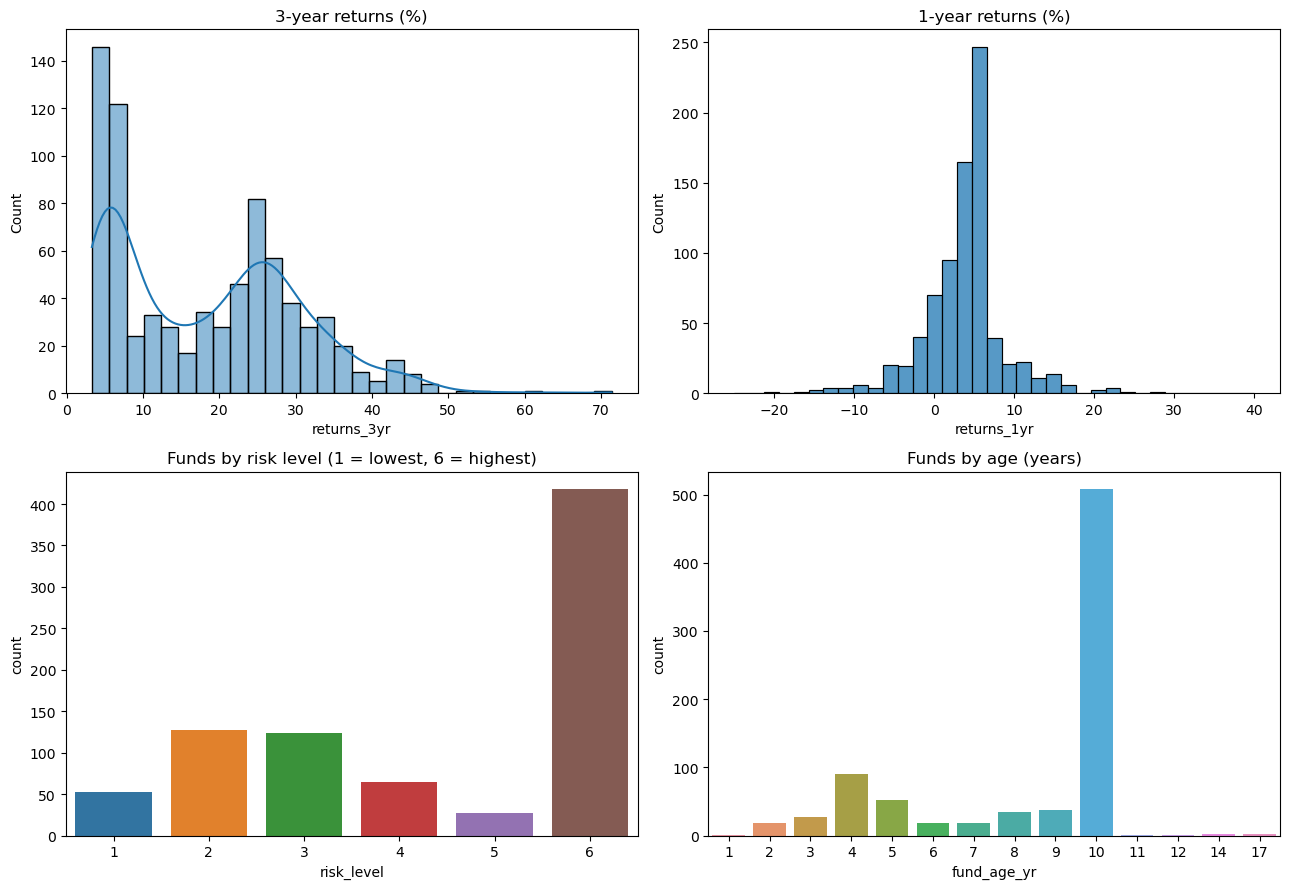

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(df["returns_3yr"].dropna(), bins=30, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("3-year returns (%)")
sns.histplot(df["returns_1yr"].dropna(), bins=35, binrange=(-25, 40), ax=axes[0, 1])
axes[0, 1].set_title("1-year returns (%)")
sns.countplot(x="risk_level", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Funds by risk level (1 = lowest, 6 = highest)")
sns.countplot(x="fund_age_yr", data=df, ax=axes[1, 1])
axes[1, 1].set_title("Funds by age (years)")
plt.tight_layout()
plt.show()

In [18]:
print(df[["returns_1yr", "returns_3yr", "expense_ratio", "fund_age_yr", "fund_size_cr"]].skew().round(2))
print(df["risk_level"].value_counts().sort_index())
print("Funds with age exactly 10:", (df["fund_age_yr"] == 10).sum(),
      f"({(df['fund_age_yr'] == 10).mean()*100:.1f}%)")
print("Funds with negative 1-year return:", (df["returns_1yr"] < 0).sum(),
      "of", df["returns_1yr"].notna().sum())

returns_1yr      8.37
returns_3yr      0.53
expense_ratio    0.76
fund_age_yr     -0.98
fund_size_cr     3.60
dtype: float64
1     53
2    127
3    124
4     65
5     27
6    418
Name: risk_level, dtype: int64
Funds with age exactly 10: 508 (62.4%)
Funds with negative 1-year return: 122 of 800


**Interpretation**
- **3-year returns** are not a single bell shape. The histogram has two peaks, around 5–10% (mostly Debt funds) and 25–30% (mostly Equity funds), because the dataset mixes low-risk and high-risk fund types.
- **1-year returns** are very skewed (skewness 8.37) because of one extreme value, and 122 of 800 funds (15.2%) have a negative 1-year return. A fund can look strong over 3 years and still be losing money now, which is why consistency matters in my score.
- **Risk level** is unbalanced: level 6 has 418 funds (about half of all funds), while level 5 has only 27.
- **Fund age** is unusual: 508 funds (62.4%) have an age of exactly 10, and the next most common age has only 91. This suggests the source caps age at 10 years, so the age column cannot separate older funds from each other. I keep this in mind for the age factor in my score.
- **Expense ratio** is mildly right-skewed (0.76), and **fund size** is strongly right-skewed (3.60), meaning a few very large funds.

### 2.3 Outliers and surprising patterns
I use the IQR rule (values beyond 1.5 × IQR from the quartiles) to count outliers, then look at the most extreme funds and the 3-year return spread by category.

In [19]:
rows = []
for c in ["returns_1yr", "returns_3yr", "expense_ratio", "fund_age_yr", "fund_size_cr", "sd"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append([c, round(low, 2), round(high, 2), int(((df[c] < low) | (df[c] > high)).sum())])
print(pd.DataFrame(rows, columns=["column", "lower_limit", "upper_limit", "outliers"]))

          column  lower_limit  upper_limit  outliers
0    returns_1yr        -4.65        11.75        87
1    returns_3yr       -24.70        57.70         2
2  expense_ratio        -0.77         2.11         4
3    fund_age_yr         0.00        16.00         2
4   fund_size_cr     -5290.38      9284.62        94
5             sd       -19.25        37.85         1


                                         scheme_name category  returns_1yr
89                    Bank of India Credit Risk Fund     Debt        130.8
97   Bank of India Short Term Income – Direct Growth     Debt         28.3
321                    ICICI Pru Infrastructure Fund   Equity         24.3
                       scheme_name                      sub_category  \
608           Quant Small Cap Fund            Small Cap Mutual Funds   
603      Quant Infrastructure Fund  Sectoral / Thematic Mutual Funds   
609  Quant Tax Plan- Direct Growth                 ELSS Mutual Funds   

     returns_3yr  risk_level  
608         71.4           6  
603         61.5           6  
609         54.9           6  
                      scheme_name  \
638               SBI Liquid Fund   
627        SBI Equity Hybrid Fund   
223  HDFC Balanced Advantage Fund   

                                       sub_category  fund_size_cr  
638                             Liquid Mutual Funds       57052.0  
62

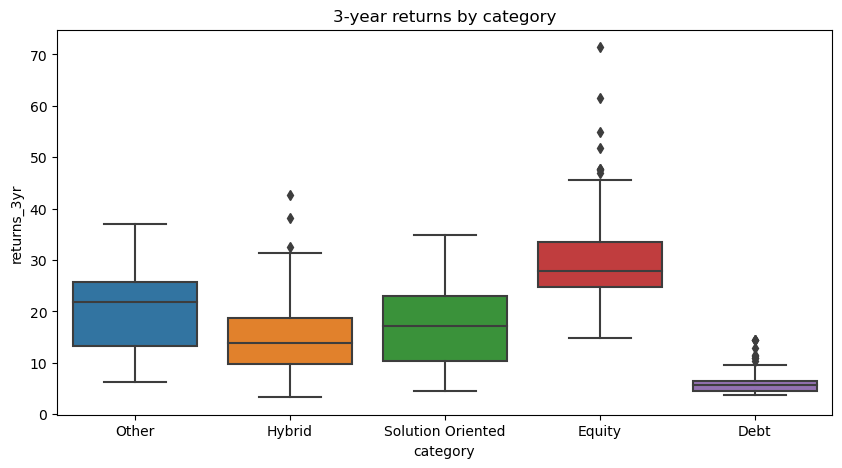

In [20]:
print(df.nlargest(3, "returns_1yr")[["scheme_name", "category", "returns_1yr"]])
print(df.nlargest(3, "returns_3yr")[["scheme_name", "sub_category", "returns_3yr", "risk_level"]])
print(df.nlargest(3, "fund_size_cr")[["scheme_name", "sub_category", "fund_size_cr"]])
print(df.nlargest(3, "expense_ratio")[["scheme_name", "expense_ratio"]])

plt.figure(figsize=(10, 5))
sns.boxplot(x="category", y="returns_3yr", data=df)
plt.title("3-year returns by category")
plt.show()

**Interpretation**
- **1-year returns:** 87 funds are outliers. The most extreme is Bank of India Credit Risk Fund at 130.8%, a Debt fund with a standard deviation of 77.72, which is almost certainly a data error. I treat it as unreliable.
- **Fund size:** 94 outliers, led by SBI Liquid Fund (₹57,052 crore). Liquid funds and large balanced funds are simply very large, so these are real, not errors.
- **3-year returns:** only 2 outliers overall, led by Quant Small Cap Fund (71.4%) and Quant Infrastructure Fund (61.5%), both risk level 6. High returns come with the highest risk level.
- **Expense ratio:** 4 outliers, led by Taurus Flexi Cap Fund at 2.59%, which is very expensive compared with the median of 0.62%.
- **By category (boxplot):** Equity has high returns and a wide spread, while Debt is low and tight. This explains why the overall data has two peaks.
- **Surprise:** a fund's 1-year return can be negative even when its 3-year return is high, so I must check consistency, not just returns.